## Solution for Assignment 02 Question 3

### Setup

In [29]:
import torch
import torch.nn as nn
from torchvision.models import resnet18
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import copy

SEED = 0

### CONSTANTS ###
BATCH_SIZE = 256
EPOCHS = 10
LR = 0.0001


### MODEL ###
# Initialize the ResNet18 model with random weights using torchvision
resnet18_model = resnet18(weights=None)
# Adjust input and output layers to work with FMNIST
resnet18_model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
resnet18_model.fc = nn.Linear(resnet18_model.fc.in_features, 10)

In [38]:
### DATA ###

# Transform to convert FMNIST data into normalized tensors
fmnist_data_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


# Init train and test datasets
train_data = datasets.FashionMNIST(
    root='/datasets/FMNIST/',
    train=True,
    download=True,
    transform=fmnist_data_transform
)

test_data = datasets.FashionMNIST(
    root="/datasets/FMNIST/",
    train=False,
    download=True,
    transform=fmnist_data_transform,
)

# Will need validation for early stopping. To do that, I split the training dataset
# 90% for training, 10% for validation
val_size = int(0.1 * len(train_data))
train_size = len(train_data) - val_size

train_set, val_set = torch.utils.data.random_split(
    train_data, [train_size, val_size], generator=torch.Generator().manual_seed(SEED)
)

# Define dataloaders
FMNIST_train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
FMNIST_val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
FMNIST_test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

### a) Training with L2 Regularization

In [ ]:
### L2 Regularization TRAIN and TEST ###
LAMBDA = 0.0001


# Training with l2 regularization
def train_l2_regularize(
    epochs, learning_rate, model, train_loader, test_loader, lambda_val
):
    test_accs = []
    train_accs = []
    # Define the optimizer, use Adam with no weight decay (L2 regularization is added manually)
    optim = torch.optim.Adam(
        params=model.parameters(), lr=learning_rate, weight_decay=0
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()
            # Add l2 regularization term defined as lambda / 2 * sum of squared parameters
            loss += lambda_val * sum((p**2).sum() for p in model.parameters()) / 2

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)
    return train_accs, test_accs


l2_regularization_model = copy.deepcopy(resnet18_model)
train_accs_l2, test_accs_l2 = train_l2_regularize(
    EPOCHS, LR, l2_regularization_model, FMNIST_train_loader, FMNIST_test_loader, LAMBDA
)

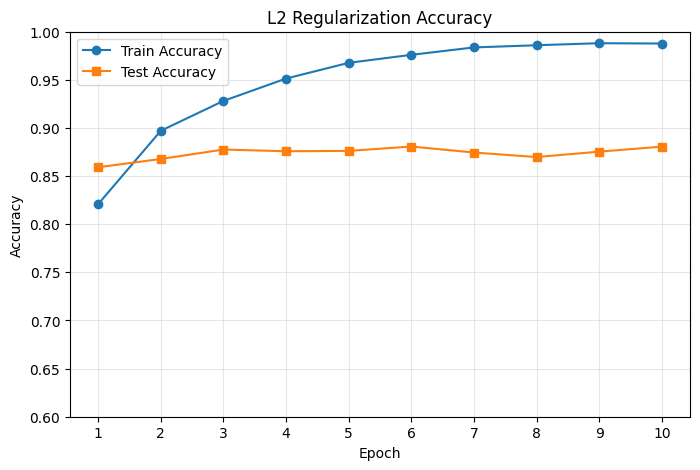

In [ ]:
# Plotting script
import matplotlib.pyplot as plt

def plot_accs(title, train_accs, test_accs):
    epochs = range(1, len(train_accs) + 1)
    
    plt.figure(figsize=(8, 5))

    plt.plot(epochs, train_accs, marker="o", label="Train Accuracy")
    plt.plot(epochs, test_accs, marker="s", label="Test Accuracy")

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.xticks(epochs)
    plt.ylim(min(0.6, 0.95 * min(min(train_accs), min(test_accs))), 1)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
plot_accs("L2 Regularization Accuracy", train_accs_l2, test_accs_l2)

### b) Training with Adam with weight decay

In [ ]:
### Weight-Decay Adam TRAIN and TEST ###
weight_decay = LAMBDA


# Training with weight-decay Adam
def train_weight_decay(
    epochs, learning_rate, model, train_loader, test_loader, weight_decay_const
):
    test_accs = []
    train_accs = []
    # Define the optimizer, use Adam with weight decay
    optim = torch.optim.Adam(
        params=model.parameters(), lr=learning_rate, weight_decay=weight_decay_const
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)
    return train_accs, test_accs


weight_decay_model = copy.deepcopy(resnet18_model)
train_accs_wd, test_accs_wd = train_weight_decay(
    EPOCHS,
    LR,
    weight_decay_model,
    FMNIST_train_loader,
    FMNIST_test_loader,
    weight_decay,
)

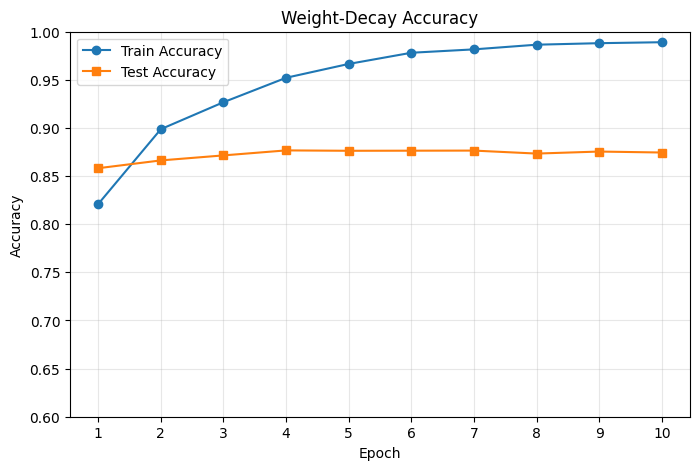

In [35]:
plot_accs("Weight-Decay Accuracy", train_accs_wd, test_accs_wd)

### c) AdamW with weight decay

In [ ]:
### Weight-Decay AdamW TRAIN and TEST ###
weight_decay_AdamW = LAMBDA


# Training with weight-decay AdamW
def train_weight_decay_AdamW(
    epochs, learning_rate, model, train_loader, test_loader, weight_decay_const
):
    test_accs = []
    train_accs = []
    # Define the optimizer, use AdamW with weight decay
    optim = torch.optim.AdamW(
        params=model.parameters(), lr=learning_rate, weight_decay=weight_decay_const
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)
    return train_accs, test_accs


weight_decay_AdamW_model = copy.deepcopy(resnet18_model)
train_accs_wd_AdamW, test_accs_wd_AdamW = train_weight_decay_AdamW(
    EPOCHS,
    LR,
    weight_decay_AdamW_model,
    FMNIST_train_loader,
    FMNIST_test_loader,
    weight_decay_AdamW,
)

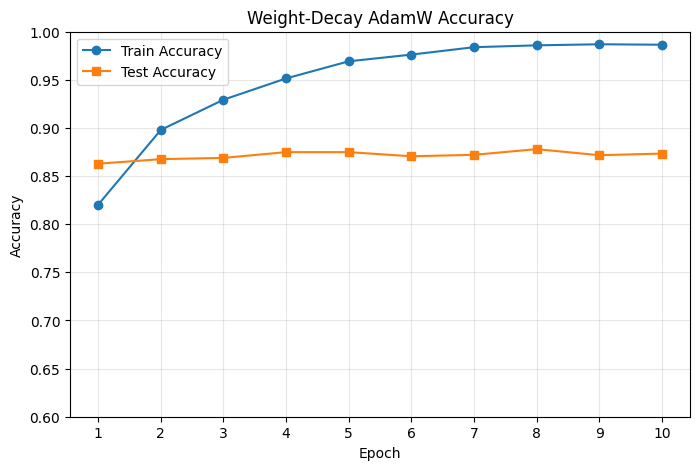

In [37]:
plot_accs("Weight-Decay AdamW Accuracy", train_accs_wd_AdamW, test_accs_wd_AdamW)

### d) All methods with early stopping

In [ ]:
### L2 Regularization TRAIN and TEST  with early stopping ###
LAMBDA = 0.0001


# Training with l2 regularization with early stopping
def train_l2_regularize_early_stop(
    epochs,
    learning_rate,
    model,
    train_loader,
    valid_loader,
    test_loader,
    lambda_val,
    patience=2,
):
    test_accs = []
    train_accs = []
    valid_loss = []

    best_val_loss = float("inf")
    epochs_without_better_valid_loss = 0

    # Define the optimizer, use Adam with no weight decay (L2 regularization is added manually)
    optim = torch.optim.Adam(
        params=model.parameters(), lr=learning_rate, weight_decay=0
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()
            # Add l2 regularization term defined as lambda / 2 * sum of squared parameters
            loss += lambda_val * sum((p**2).sum() for p in model.parameters()) / 2

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)

        # Validation for early stopping
        total_val_loss = 0
        total_val_samples = 0

        # Calculate the average validation loss
        with torch.no_grad():
            for features, labels in valid_loader:
                output_model_val = model(features)
                val_loss = criterion(output_model_val, labels)
                total_val_loss += val_loss.item() * output_model_val.size(0)
                total_val_samples += output_model_val.size(0)

        avg_val_loss = total_val_loss / total_val_samples
        valid_loss.append(avg_val_loss)

        # Check if the current validation loss is the best one
        if avg_val_loss < best_val_loss:
            # Update the best validation loss
            best_val_loss = avg_val_loss
            epochs_without_better_valid_loss = 0
        else:
            # No improvement in validation loss
            epochs_without_better_valid_loss += 1
            # If the number of epochs without improvement exceeds the patience, stop early
            if epochs_without_better_valid_loss >= patience:
                print(f"Early stopping at epoch {_ + 1}")
                break

    return train_accs, test_accs, valid_loss


l2_regularization_model = copy.deepcopy(resnet18_model)
train_accs_l2_early_stop, test_accs_l2_early_stop, valid_loss_l2_early_stop = (
    train_l2_regularize_early_stop(
        EPOCHS,
        LR,
        l2_regularization_model,
        FMNIST_train_loader,
        FMNIST_val_loader,
        FMNIST_test_loader,
        LAMBDA,
    )
)

Early stopping at epoch 5


In [44]:
### Weight-Decay Adam TRAIN and TEST with early stopping ###
weight_decay = LAMBDA

# Training with Weight-Decay Adam and early stopping
def train_weight_decay_early_stop(
    epochs,
    learning_rate,
    model,
    train_loader,
    valid_loader,
    test_loader,
    weight_decay_const,
    patience=2,
):
    test_accs = []
    train_accs = []
    valid_loss = []

    best_val_loss = float("inf")
    epochs_without_better_valid_loss = 0

    # Define the optimizer, use Adam
    optim = torch.optim.Adam(
        params=model.parameters(), lr=learning_rate, weight_decay=weight_decay_const
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)

        # Validation for early stopping
        total_val_loss = 0
        total_val_samples = 0

        # Calculate the average validation loss
        with torch.no_grad():
            for features, labels in valid_loader:
                output_model_val = model(features)
                val_loss = criterion(output_model_val, labels)
                total_val_loss += val_loss.item() * output_model_val.size(0)
                total_val_samples += output_model_val.size(0)

        avg_val_loss = total_val_loss / total_val_samples
        valid_loss.append(avg_val_loss)

        # Check if the current validation loss is the best one
        if avg_val_loss < best_val_loss:
            # Update the best validation loss
            best_val_loss = avg_val_loss
            epochs_without_better_valid_loss = 0
        else:
            # No improvement in validation loss
            epochs_without_better_valid_loss += 1
            # If the number of epochs without improvement exceeds the patience, stop early
            if epochs_without_better_valid_loss >= patience:
                print(f"Early stopping at epoch {_ + 1}")
                break

    return train_accs, test_accs, valid_loss


weight_decay_model = copy.deepcopy(resnet18_model)
(
    train_accs_weight_decay_early_stop,
    test_accs_weight_decay_early_stop,
    valid_loss_weight_decay_early_stop,
) = train_weight_decay_early_stop(
    EPOCHS,
    LR,
    weight_decay_model,
    FMNIST_train_loader,
    FMNIST_val_loader,
    FMNIST_test_loader,
    weight_decay,
)

Early stopping at epoch 4
[0.37918207375208535, 0.3423721745808919, 0.34827263649304707, 0.3652792443434397]


In [45]:
### Weight-Decay Adam TRAIN and TEST with early stopping ###
weight_decay = LAMBDA


# Training with Weight-Decay AdamW and early stopping
def train_weight_decay_AdamW_early_stop(
    epochs,
    learning_rate,
    model,
    train_loader,
    valid_loader,
    test_loader,
    weight_decay_const,
    patience=2,
):
    test_accs = []
    train_accs = []
    valid_loss = []

    best_val_loss = float("inf")
    epochs_without_better_valid_loss = 0

    # Define the optimizer, use AdamW
    optim = torch.optim.AdamW(
        params=model.parameters(), lr=learning_rate, weight_decay=weight_decay_const
    )
    # The loss criterion is the cross entropy loss
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for _ in range(epochs):
        total = 0
        correct = 0
        model.train()

        # Iterate over batches of data
        for features, labels in train_loader:
            # Calculate original cross entropy loss
            output_model = model(features)
            predictions = output_model.argmax(axis=1)
            loss = criterion(output_model, labels)
            total += output_model.size(0)
            correct += (predictions == labels).sum().item()

            # Backpropagate
            optim.zero_grad()
            loss.backward()
            optim.step()

        train_acc = correct / total
        train_accs.append(train_acc)

        # Evaluate on the test set
        model.eval()

        total = 0
        correct = 0
        with torch.no_grad():
            for features, labels in test_loader:
                output_model_test = model(features)
                predictions = output_model_test.argmax(axis=1)
                total += output_model_test.size(0)
                correct += (predictions == labels).sum().item()

        test_acc = correct / total
        test_accs.append(test_acc)

        # Validation for early stopping
        total_val_loss = 0
        total_val_samples = 0

        # Calculate the average validation loss
        with torch.no_grad():
            for features, labels in valid_loader:
                output_model_val = model(features)
                val_loss = criterion(output_model_val, labels)
                total_val_loss += val_loss.item() * output_model_val.size(0)
                total_val_samples += output_model_val.size(0)

        avg_val_loss = total_val_loss / total_val_samples
        valid_loss.append(avg_val_loss)

        # Check if the current validation loss is the best one
        if avg_val_loss < best_val_loss:
            # Update the best validation loss
            best_val_loss = avg_val_loss
            epochs_without_better_valid_loss = 0
        else:
            # No improvement in validation loss
            epochs_without_better_valid_loss += 1
            # If the number of epochs without improvement exceeds the patience, stop early
            if epochs_without_better_valid_loss >= patience:
                print(f"Early stopping at epoch {_ + 1}")
                break

    return train_accs, test_accs, valid_loss


weight_decay_AdamW_model = copy.deepcopy(resnet18_model)
(
    train_accs_weight_decay_AdamW_early_stop,
    test_accs_weight_decay_AdamW_early_stop,
    valid_loss_weight_decay_AdamW_early_stop,
) = train_weight_decay_early_stop(
    EPOCHS,
    LR,
    weight_decay_AdamW_model,
    FMNIST_train_loader,
    FMNIST_val_loader,
    FMNIST_test_loader,
    weight_decay,
)


Early stopping at epoch 4
